## Phase 1: Data Selection, Cleaning, and Exploratory Data Analysis (EDA)
### 1.1 Environment Setup & Data Loading

In [46]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Set a global random seed for reproducibility (Required by project guidelines)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure visualization style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Load the dataset
file_path = 'UCI_Credit_Card.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully from local file.")
else:
    print("Dataset file is not here :]")


Dataset loaded successfully from local file.


In [47]:
print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()

Dataset Shape: 30,000 rows and 25 columns.


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


### 1.2 Data Cleaning
We drop the `ID` column, rename `PAY_0` to `PAY_1` and the target column to `DEFAULT`, remove duplicates, and group undocumented codes in `EDUCATION` (0, 5, 6 $\rightarrow$ 4) and `MARRIAGE` (0 $\rightarrow$ 3).

In [48]:
# 1. Drop ID and rename columns
df.drop(columns=['ID'], inplace=True)
df.rename(columns={'PAY_0': 'PAY_1', 'default.payment.next.month': 'DEFAULT'}, inplace=True)

In [49]:
# 2. Check missing values and remove duplicates
print("Missing values:", df.isnull().sum().sum())
print("Duplicates before:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

Missing values: 0
Duplicates before: 35


In [50]:
# 3. Clean undocumented values (Hidden missing values)
df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}, inplace=True)
df['MARRIAGE'].replace({0: 3}, inplace=True)

print("EDUCATION counts:\n", df['EDUCATION'].value_counts())
print("\nMARRIAGE counts:\n", df['MARRIAGE'].value_counts())

EDUCATION counts:
 EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

MARRIAGE counts:
 MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64


C:\Users\USER\AppData\Local\Temp\ipykernel_21700\3038516333.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}, inplace=True)
C:\Users\USER\AppData\Local\Temp\ipykernel_21700\3038516333.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.



**Cleaning Summary:**
* Removed the `ID` column and standardized column names (`PAY_1` and `DEFAULT`).
* Confirmed `0` missing values and removed `35` duplicate rows.
* Merged undocumented values in `EDUCATION` (`0, 5, 6`) into category `4` (Others) and in `MARRIAGE` (`0`) into category `3` (Others).

### 1.3 Exploratory Data Analysis (EDA)
#### A. Target Variable Distribution (`DEFAULT`)
We check the distribution of the target variable to quantify the class imbalance between non-defaulters (`0`) and defaulters (`1`).

DEFAULT
0    77.874187
1    22.125813
Name: proportion, dtype: float64


C:\Users\USER\AppData\Local\Temp\ipykernel_21700\4176022244.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='DEFAULT', palette='Set2')


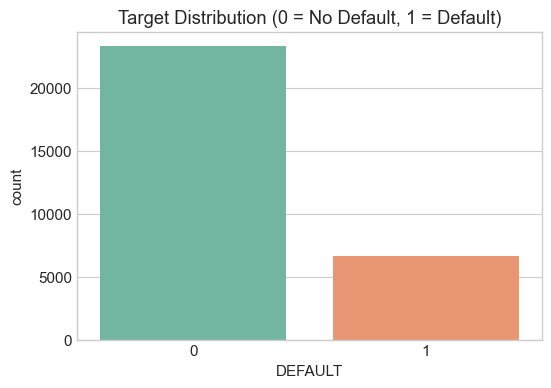

In [51]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='DEFAULT', palette='Set2')
plt.title('Target Distribution (0 = No Default, 1 = Default)')

# Print exact percentages
print(df['DEFAULT'].value_counts(normalize=True) * 100)
plt.show()

**Observation:** 
The dataset is imbalanced: **77.88%** of clients did not default (`0`), while **22.12%** defaulted (`1`). This confirms the need for `Stratified Train/Test Split`, `class_weight='balanced'`, and evaluating models using **Recall, Precision, F1-score, and ROC-AUC** rather than accuracy alone.

#### B. Demographic & Sensitive Attributes Analysis
We explore how default rates vary across sensitive demographic groups (`SEX`, `EDUCATION`, `MARRIAGE`, and `AGE`), which also establishes the baseline for our Phase 6 Fairness Audit.

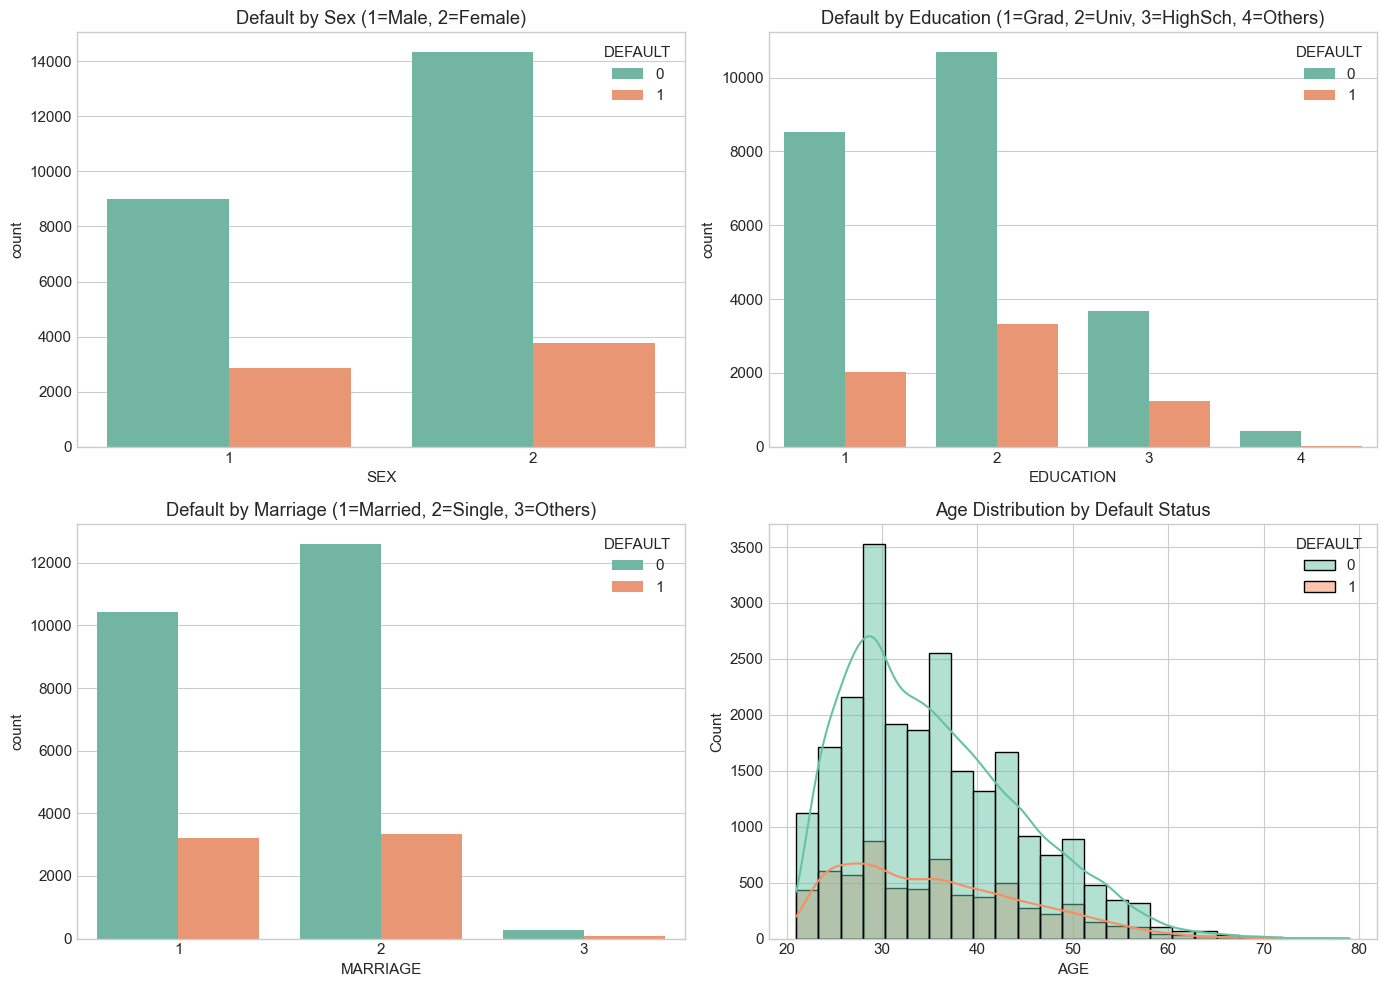


Default Rate (%) by SEX:
SEX
1    24.16
2    20.79
Name: DEFAULT, dtype: float64

Default Rate (%) by EDUCATION:
EDUCATION
1    19.24
2    23.74
3    25.17
4     7.05
Name: DEFAULT, dtype: float64

Default Rate (%) by MARRIAGE:
MARRIAGE
1    23.46
2    20.95
3    23.61
Name: DEFAULT, dtype: float64


In [52]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='SEX', hue='DEFAULT', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Default by Sex (1=Male, 2=Female)')

sns.countplot(data=df, x='EDUCATION', hue='DEFAULT', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Default by Education (1=Grad, 2=Univ, 3=HighSch, 4=Others)')

sns.countplot(data=df, x='MARRIAGE', hue='DEFAULT', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Default by Marriage (1=Married, 2=Single, 3=Others)')

sns.histplot(data=df, x='AGE', hue='DEFAULT', bins=25, kde=True, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Age Distribution by Default Status')

plt.tight_layout()
plt.show()

# Print exact default rate (%) per group for the report
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\nDefault Rate (%) by {col}:")
    print((df.groupby(col)['DEFAULT'].mean() * 100).round(2))

**Observations:**
* **Sex (`SEX`):** Males (`1`) have a noticeably higher default rate (**~24.2%**) compared to females (`2`, **~20.8%**), indicating a potential demographic disparity to monitor during the Fairness Audit.
* **Education (`EDUCATION`):** Clients with high school (`3`) or university (`2`) education show higher default rates than graduate school (`1`) clients.
* **Marriage (`MARRIAGE`):** Married clients (`1`) exhibit a slightly higher default proportion than single clients (`2`).

#### C. Financial Features & Correlation Matrix
We examine the distribution of credit limits (`LIMIT_BAL`), repayment status (`PAY_1`), and the correlation matrix across all features to detect multicollinearity.

C:\Users\USER\AppData\Local\Temp\ipykernel_21700\3676413328.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='DEFAULT', y='LIMIT_BAL', palette='Set2', ax=axes[0])


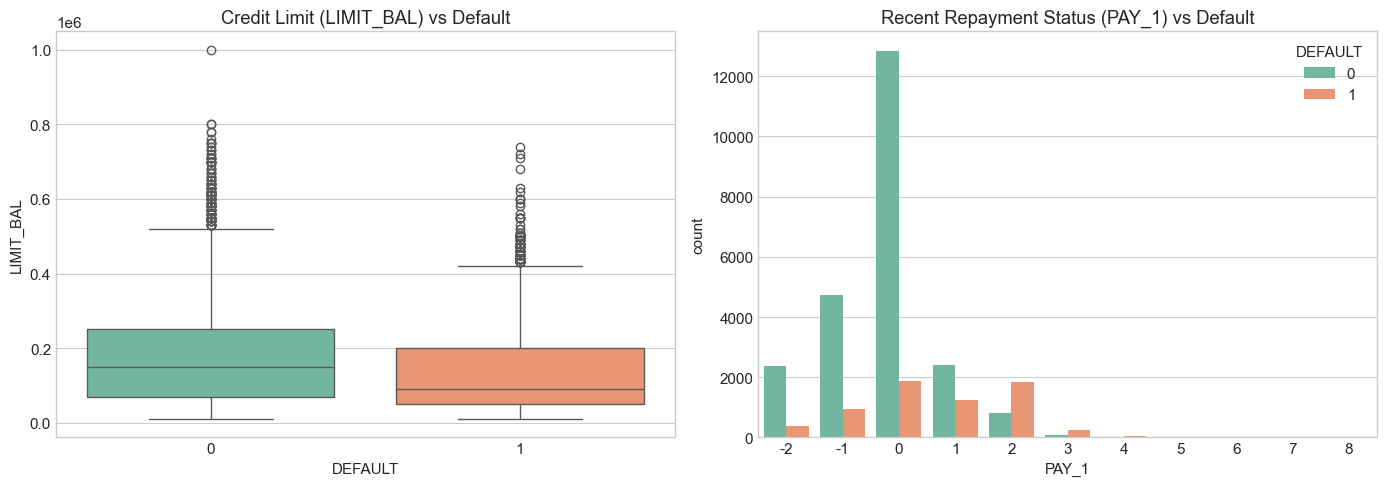

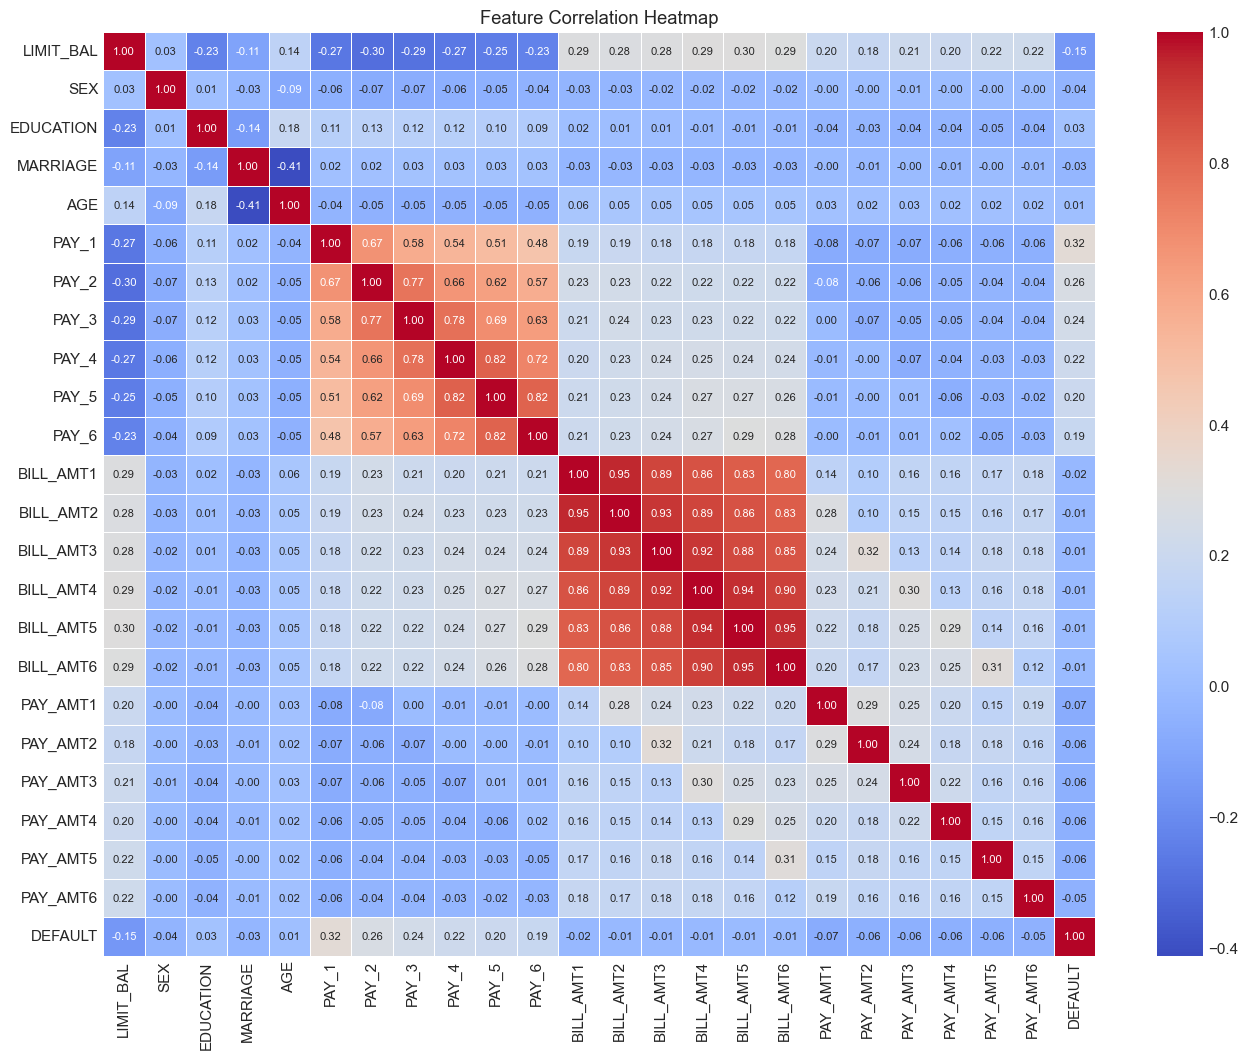

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DEFAULT', y='LIMIT_BAL', palette='Set2', ax=axes[0])
axes[0].set_title('Credit Limit (LIMIT_BAL) vs Default')

sns.countplot(data=df, x='PAY_1', hue='DEFAULT', palette='Set2', ax=axes[1])
axes[1].set_title('Recent Repayment Status (PAY_1) vs Default')

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, annot_kws={"size": 8})
plt.title('Feature Correlation Heatmap')
plt.show()

**Observations:**
* **Credit Limit & Outliers:** Defaulters generally have lower credit limits (`LIMIT_BAL`). Financial features contain high upper-bound outliers (wealthy clients), confirming the need for feature scaling (`StandardScaler`).
* **Strongest Predictor (`PAY_1`):** Repayment status in the most recent month (`PAY_1`) has the strongest positive correlation with `DEFAULT` (**0.32**). Clients with delayed payments (`PAY_1 >= 1`) have a drastically higher probability of default.
* **Multicollinearity:** Bill amount columns (`BILL_AMT1` to `BILL_AMT6`) are heavily correlated with each other ($r > 0.80$), and `PAY_1` to `PAY_6` show moderate-to-high correlation. This is critical to note when interpreting **Permutation Importance** and **Linear Coefficients** in Phase 4, as correlated features can share or dilute importance scores.

#### D. Summary Statistics & Bill/Payment Distributions
We display the descriptive statistics (`mean`, `std`, `min`, `max`) to inspect value ranges and check the skewness of bill and payment amounts.

,mean,std,min,50%,max
LIMIT_BAL,167442.01,129760.14,10000.0,140000.0,1000000.0
SEX,1.60,0.49,1.0,2.0,2.0
EDUCATION,1.84,0.74,1.0,2.0,4.0
MARRIAGE,1.56,0.52,1.0,2.0,3.0
AGE,35.49,9.22,21.0,34.0,79.0
PAY_1,-0.02,1.12,-2.0,0.0,8.0
PAY_2,-0.13,1.20,-2.0,0.0,8.0
PAY_3,-0.16,1.20,-2.0,0.0,8.0
PAY_4,-0.22,1.17,-2.0,0.0,8.0
PAY_5,-0.26,1.13,-2.0,0.0,8.0


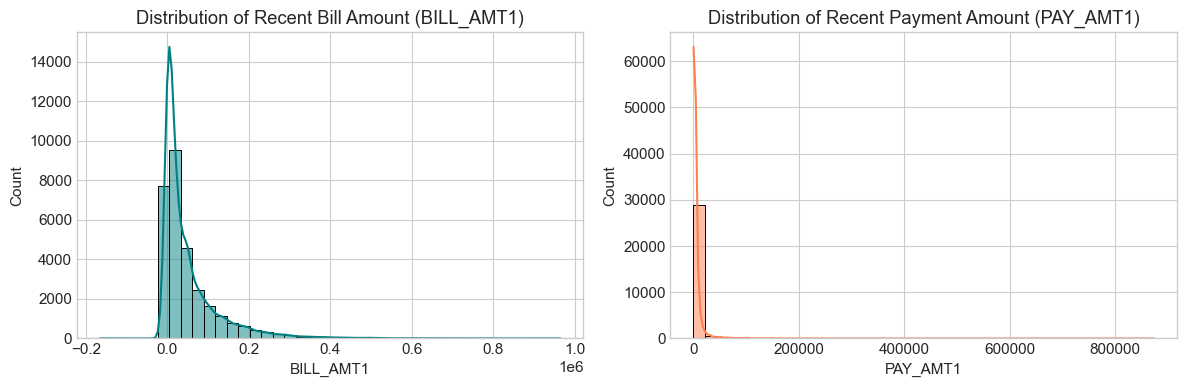

In [58]:
# 1. Summary statistics table (transposed for easy reading)
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

# 2. Distribution of most recent Bill and Payment amounts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['BILL_AMT1'], bins=40, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Recent Bill Amount (BILL_AMT1)')

sns.histplot(df['PAY_AMT1'], bins=40, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Recent Payment Amount (PAY_AMT1)')
plt.tight_layout()
plt.show()

**Observations:**
* **Scale Differences & Negative Bills:** Features vary wildly in scale (`AGE` ranges from `21` to `79`, while `LIMIT_BAL` reaches `1,000,000`), confirming that `StandardScaler` is mandatory. Minimum values in `BILL_AMT` are negative, which validly represents credit balances (overpayments).
* **Right Skewness:** Both `BILL_AMT1` and `PAY_AMT1` are heavily right-skewed, with most clients having moderate bills/payments and a few extreme high-value outliers.

### 1.4 One-Hot Encoding, Stratified Split, and Feature Scaling
We apply One-Hot Encoding (`drop_first=True`) to the nominal categorical features (`SEX`, `EDUCATION`, `MARRIAGE`), while keeping `PAY_1`–`PAY_6` as ordinal numeric features. Then, we perform a **Stratified Train/Test Split** (80/20) and fit `StandardScaler` strictly on the training data to prevent data leakage.

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. One-Hot Encode nominal categorical columns (drop_first=True prevents multicollinearity)
df_encoded = pd.get_dummies(df, columns=['SEX', 'EDUCATION', 'MARRIAGE'], drop_first=True, dtype=int)

In [55]:
# 2. Separate features (X) and target (y)
X = df_encoded.drop(columns=['DEFAULT'])
y = df_encoded['DEFAULT']

In [56]:
# 3. Stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [57]:
# 4. Scale features (Fit ONLY on X_train to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print(f"Train shape: {X_train_scaled.shape} | Default rate: {y_train.mean()*100:.2f}%")
print(f"Test shape:  {X_test_scaled.shape}  | Default rate: {y_test.mean()*100:.2f}%")
X_train_scaled.head(3)


Train shape: (23972, 26) | Default rate: 22.13%
Test shape:  (5993, 26)  | Default rate: 22.13%


,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
27420,1.022024,-0.050264,-1.771947,-1.566494,-1.544266,-1.530037,-1.538794,-1.492534,-0.700030,-0.694464,...,-0.294973,-0.320892,-0.318684,-0.289319,-1.22974,1.063412,-0.438837,-0.126574,-1.067965,-0.114834
15350,-0.903020,0.167213,1.793738,1.781057,1.818359,1.906811,2.010259,2.005012,-0.049079,-0.005582,...,-0.294973,-0.093938,-0.318684,-0.223376,0.81318,-0.940370,2.278753,-0.126574,-1.067965,8.708234
26641,-0.672015,-1.355126,-0.880526,-0.729606,-0.703609,-0.670825,0.235732,0.256239,-0.693968,-0.688208,...,-0.244835,-0.291254,-0.318684,-0.232278,-1.22974,-0.940370,-0.438837,-0.126574,0.936361,-0.114834


**Preprocessing Summary:**
* Both training (`23,972` rows) and testing (`5,993` rows) sets maintain the exact same default ratio (**22.12%**), confirming a successful stratified split.
* Features are standardized (`mean = 0`, `std = 1`) and stored as DataFrames (`X_train_scaled`, `X_test_scaled`) so feature names remain intact for **SHAP**, **LIME**, and **Permutation Importance** in later phases.